In [247]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


# Importing Separately to show that i am not using scikitlearn for anything other than the permitted
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, confusion_matrix,classification_report, f1_score,precision_score, recall_score)
# Allowed only for the Verification part.

np.random.seed(0)

In [248]:
### Preparation Stage: Data Overview and Analysis ###

# Data import
data = pd.read_csv("MSO2520_dataset.csv")

# Removing any potential null/na entries from our dataset.
o1 = len(data)
data = data.dropna()
o2 = len(data)

# Fancy-ish way to determine a difference in before and after data length
if (o1 == o2):
    print("No Empty Entries Found (Rows: Before = After = 2597)")
else:
    print("Before Purge", o1)
    print("After NA Purge", o2)

# Potentially Cleaned data Showcase
print(data.shape)
print(data.head())
print(data.describe())

No Empty Entries Found (Rows: Before = After = 2597)
(2597, 38)
   Output_information   ALT   AST  Albumin    ALP  Amilase      CK.MB  \
0                 1.0  17.9  21.0    35.40   48.0     15.0  20.900000   
1                 1.0  12.0  32.0    34.55   60.0     85.0  27.000000   
2                 1.0  22.0  28.0    36.95   45.0     84.0  32.749296   
3                 1.0  48.0  48.0    42.29  115.0    179.0  43.300000   
4                 1.0  13.0  27.0    40.00  115.0     44.0  27.000000   

   Direct_Bilirubin  Glucose  Creatinine  ...    CRP  D.Dimer  Ferritin  \
0          0.220000    235.0        1.89  ...   98.0   1277.0     395.0   
1          0.120000    111.0        1.82  ...   62.0   1277.0     395.0   
2          0.272418    109.0        1.61  ...  108.0   1277.0     395.0   
3          0.130000     79.0        1.41  ...   72.0   1277.0     395.0   
4          0.080000    287.0        0.87  ...   58.0   1277.0     395.0   

   Fibrinogen  INR    PT  Procalcitonin   ESR 

In [249]:
# Class Balance
print(data['Output_information'].value_counts())
print(data['Output_information'].value_counts(normalize = True)) # Show's how severely unbalanced this data is.
                                                                 # about a 91% to 9% Split between Negative and Positive (Heavily Favours Negative)
 
# Splitting our Data into X and y, X being our 37 Features, y being our Target
X = data.drop("Output_information", axis=1)
y = data["Output_information"]

Output_information
0.0    2364
1.0     233
Name: count, dtype: int64
Output_information
0.0    0.910281
1.0    0.089719
Name: proportion, dtype: float64


Showcasing the difference in bar-chart form


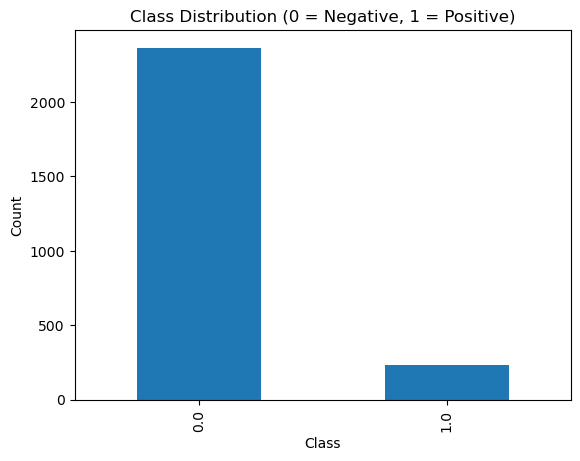

In [250]:
# Distribution Bar Chart Plot
data['Output_information'].value_counts().plot(kind='bar')
plt.title("Class Distribution (0 = Negative, 1 = Positive)")
plt.xlabel("Class")
plt.ylabel("Count")
print("Showcasing the difference in bar-chart form")
plt.show()

In [251]:
# Preprocessing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

# Standardising Data
mu = np.mean(X_train, axis=0)
sigma = np.std(X_train, axis=0)
X_train = (X_train - mu) / sigma
X_test = (X_test - mu) / sigma

X_train = np.array(X_train)
X_test = np.array(X_test)
y_train = np.array(y_train).astype(int)
y_test = np.array(y_test).astype(int)

# Printing 
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train class counts:", np.bincount(y_train.astype(int)))
print("Test class counts:", np.bincount(y_test.astype(int)))

Train shape: (2077, 37)
Test shape: (520, 37)
Train class counts: [1891  186]
Test class counts: [473  47]


### Exploratory Linear Algebra ###

In [252]:
# Covariance Matrix
X_mean = X_train.mean(axis=0)
Xc = np.array(X_train - X_mean)
C = (Xc.T @ Xc) / (Xc.shape[0] - 1)

print(C.shape)
#print(C)

(37, 37)


In [253]:
# 4. Compute Eigenvalues & Eigenvectors
eigvals, eigvecs = np.linalg.eigh(C) # Sorting Eigenvalues, theyre not sorted in order
idx = np.argsort(eigvals)[::-1]
eigvals = eigvals[idx]
eigvecs = eigvecs[:, idx]

print(eigvals)
print("Rank:", np.sum(eigvals > 1e-10))

[3.71335900e+00 3.51735926e+00 3.02457692e+00 2.79648341e+00
 2.09547127e+00 1.95949245e+00 1.65164040e+00 1.31324765e+00
 1.21141176e+00 1.16900444e+00 1.14225609e+00 1.00393178e+00
 9.89195620e-01 9.81535943e-01 9.63735929e-01 8.60280992e-01
 8.45339088e-01 8.02959053e-01 7.81977260e-01 7.37255317e-01
 6.55987280e-01 6.22984139e-01 5.78982027e-01 5.77158288e-01
 5.27338938e-01 5.18383086e-01 5.03946657e-01 4.57138591e-01
 3.96934843e-01 2.77594510e-01 1.75848400e-01 9.15985070e-02
 3.61274032e-02 3.20718334e-02 3.83287512e-03 7.09923314e-04
 6.71816393e-04]
Rank: 37


In [271]:
# 5. Epxplained Variance Ratio
explained_var_ratio = eigvals/np.sum(eigvals)
cumulative_var = np.cumsum(explained_var_ratio)
n_95 = np.argmax(cumulative_var >= 0.95)+1 # Variance of 95%, enough principal components to preserve 95% of the information in our Data

print("Explained Variance Ratio:", cumulative_var)

# Components at 95% Variance
print("Number Of Components to explain 95% Variance:", n_95)

Explained Variance Ratio: [0.10031273 0.19533073 0.27703669 0.35258094 0.40918803 0.46212178
 0.50673922 0.54221531 0.57494041 0.60651991 0.63737683 0.66449706
 0.69121921 0.71773443 0.74376881 0.76700845 0.78984445 0.8115356
 0.83265995 0.85257617 0.87029702 0.88712632 0.90276695 0.91835832
 0.93260386 0.94660747 0.96022109 0.97257024 0.98329304 0.99079198
 0.99554235 0.9980168  0.99899274 0.99985913 0.99996267 0.99998185
 1.        ]
Number Of Components to explain 95% Variance: 27


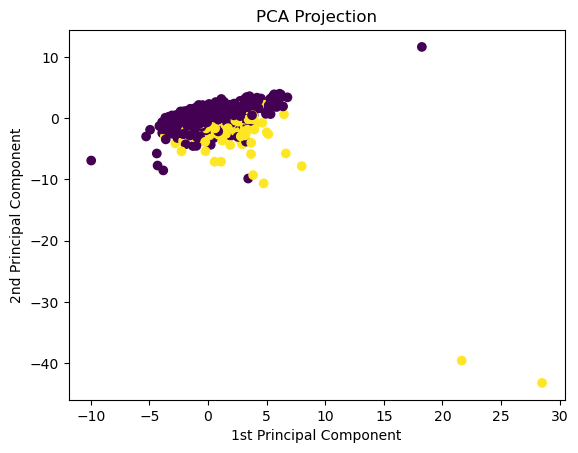

In [255]:
# PCA Section
W2 = eigvecs[:, :2]
X2 = Xc @ W2

plt.scatter(X2[:, 0], X2[:, 1], c = y_train)
plt.xlabel("1st Principal Component")
plt.ylabel("2nd Principal Component")
plt.title("PCA Projection")
plt.show()

## Notes:
# PC1 (x-axis): the direction capturing the most variance across all 37 features
# PC2 (y-axis): Captures the Second Highest Variance, orthogonal to PC1


The PCA Projection is mapping the 37-dimensional data onto a 2D plane defined by the two directions of greatest variance. Due to the overlap, we can conclude that this data is not linearly separable, and as such, we must use classification models instead. (Such as KNN, SVM, and Logistic Regression).

## Logistic Regression

In [261]:
# Defining
def sigmoid(z):
    return 1/(1+np.exp(-z))

# Cannot just use a normal Loss Function, as the Data is Severely Imbalanced.
# Must use one that accounts for weighting.

n_neg = np.sum(y_train == 0) # number of Negatives in Data = 1891
n_pos = np.sum(y_train == 1) # number of Positives in Data = 186
pos_weight = n_neg/n_pos # Positives get a 1891/186 multiplier to counteract how unbalanced the data is

def loss(X,y,w):
    z = X @ w
    p = sigmoid(z)
    weights = np.where(y == 1, pos_weight, 1)
    return -np.mean(weights *(y*np.log(p + 1e-9) + (1 - y)*np.log(1 - p + 1e-9)))

def gradient(X,y,w):
    p = sigmoid(X @ w)
    weights = np.where(y == 1, pos_weight, 1)
    return X.T @ (weights * ((p-y)/len(y)))

def train_logistics(X,y,lr=0.1,epochs=2000):
    w = np.zeros(X.shape[1])
    losses = []
    
    for i in range(epochs):
        w -= lr*gradient(X,y,w)
        c_loss = loss(X,y,w) 
        losses.append(c_loss) # Account for Losses
    return w, losses

In [268]:
w, losses = train_logistics(X_train, y_train)
pred_log = (sigmoid(X_test @ w) > 0.5).astype(int)
print("Logistic Accuracy:", np.mean(pred_log == y_test))
print("Initial Training Loss:", losses[0])
print("Final Training Loss:", losses[-1])
print(classification_report(y_test, pred_log))

Logistic Accuracy: 0.8115384615384615
Initial Training Loss: 1.0687761462969982
Final Training Loss: 0.5793476399611275
              precision    recall  f1-score   support

           0       1.00      0.79      0.88       473
           1       0.32      1.00      0.49        47

    accuracy                           0.81       520
   macro avg       0.66      0.90      0.69       520
weighted avg       0.94      0.81      0.85       520



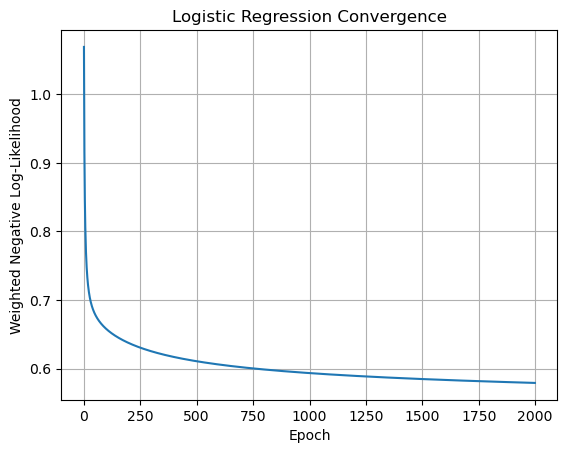

In [265]:
# Plotted Graph:

plt.figure()
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Weighted Negative Log-Likelihood")
plt.title("Logistic Regression Convergence")
plt.grid()
plt.show()

## K-Nearest-Neighbour

In [259]:
def knn_predict(X_train, y_train, x_test, k):

    distances = np.linalg.norm(X_train - x_test, axis=1)
    idx = np.argsort(distances)[:k]
    
    neighbors = y_train[idx]
    
    return np.bincount(neighbors).argmax()

# Predict Multiple Points
def knn_predict_all(X_train, y_train, X_test, k):
    return np.array([knn_predict(X_train, y_train, x, k) for x in X_test])

In [260]:
# Effects of K
k_val = range(1,21)
k_scores = [] # To Store Our K_Scores

for k in k_val:
    y_pred = knn_predict_all(X_train, y_train, X_test, k)
    accu_scores = np.mean(y_pred == y_test)
    k_scores.append(accu_scores)
    print("k =", k, "Accuracy:", accu_scores)

# Evaluating & Picking Best K
best_k = k_val[np.argmax(k_scores)]
print("Best k based on accuracy:", best_k)

y_pred = knn_predict_all(X_train, y_train, X_test, k=best_k)
print("Accuracy:", np.mean(y_pred == y_test))
print(classification_report(y_test, y_pred))

k = 1 Accuracy: 0.9557692307692308
k = 2 Accuracy: 0.9557692307692308
k = 3 Accuracy: 0.9557692307692308
k = 4 Accuracy: 0.9557692307692308
k = 5 Accuracy: 0.9634615384615385
k = 6 Accuracy: 0.9519230769230769
k = 7 Accuracy: 0.9576923076923077
k = 8 Accuracy: 0.9519230769230769
k = 9 Accuracy: 0.9538461538461539
k = 10 Accuracy: 0.95
k = 11 Accuracy: 0.948076923076923
k = 12 Accuracy: 0.948076923076923
k = 13 Accuracy: 0.9461538461538461
k = 14 Accuracy: 0.9442307692307692
k = 15 Accuracy: 0.9461538461538461
k = 16 Accuracy: 0.9384615384615385
k = 17 Accuracy: 0.9423076923076923
k = 18 Accuracy: 0.9403846153846154
k = 19 Accuracy: 0.9384615384615385
k = 20 Accuracy: 0.9365384615384615
Best k based on accuracy: 5
Accuracy: 0.9634615384615385
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       473
           1       0.89      0.68      0.77        47

    accuracy                           0.96       520
   macro avg       0.93      0

## Support Vector Machine (SVM)

In [244]:
m_svm = LinearSVC(C = 1, class_weight = 'balanced')
m_svm.fit(X_train, y_train)
y_pred_svm = m_svm.predict(X_test)

# Evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))
print("F1 score:", f1_score(y_test, y_pred_svm))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_svm))

Accuracy: 0.9076923076923077
Precision: 0.4939759036144578
Recall: 0.8723404255319149
F1 score: 0.6307692307692307

Confusion Matrix
[[431  42]
 [  6  41]]


In [245]:
w = m_svm.coef_[0]
b = m_svm.intercept_[0]

print("w =", w)
print("b =", b)
print("\nMargin =", 2 / np.linalg.norm(w))

w = [-0.14432719 -0.00861277 -0.07765261  0.08360724  0.64529982  0.22300564
  0.66879321  0.13366934  0.01825521  0.37978543  0.1708675  -0.10964172
  0.08408242 -0.19541148  1.1229368  -0.70662303 -0.36075837  0.18705559
  0.05384462 -0.30117604  0.01585675 -0.12648697 -0.39818222 -0.36544926
 -0.51774269  0.19688769  0.71829316  0.12216635  0.05101362  0.1828131
  0.9688449  -2.10753722  0.44647748 -0.2693056   0.35980043  0.02514761
 -0.43347336]
b = -0.9522819116794136

Margin = 0.6211418229534359


## Comparative Analysis

In [272]:
## Print Part of Analysis:
print("Final Analysis of Our Data:")
print("---------------------------------")
# Logistic Reg:
print("Logistic Regression Accuracy Score:", accuracy_score(y_test, pred_log))
print("Recall Score:", recall_score(y_test, pred_log))
print("F1 Score:", f1_score(y_test, pred_log))

print("---------------------------------")
# KNN: 
print("K-Nearest-Neighbour Accuracy Score:", accuracy_score(y_test, y_pred))
print("Recall Score:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("---------------------------------")
# SVM:
print("Support Vector Machine (SVM) Accuracy Score:", accuracy_score(y_test, y_pred_svm))
print("Recall Score:", recall_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm))

Final Analysis of Our Data:
---------------------------------
Logistic Regression Accuracy Score: 0.8115384615384615
Recall Score: 1.0
F1 Score: 0.4895833333333333
---------------------------------
K-Nearest-Neighbour Accuracy Score: 0.9634615384615385
Recall Score: 0.6808510638297872
F1 Score: 0.7710843373493976
---------------------------------
Support Vector Machine (SVM) Accuracy Score: 0.9076923076923077
Recall Score: 0.8723404255319149
F1 Score: 0.6307692307692307
